1. Import Libraries

In [ ]:
# Import pandas for handling the dataset
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib for graphs
import matplotlib.pyplot as plt

# Import seaborn for data visualization
import seaborn as sns

# Import train_test_split to split the dataset
from sklearn.model_selection import train_test_split

# Import StandardScaler to scale input features
from sklearn.preprocessing import StandardScaler

# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Import the file upload utility from Google Colab
from google.colab import files

# Allow graphs to appear inside the notebook
%matplotlib inline

# Print confirmation
print("Libraries imported successfully!")

Libraries imported successfully!


2. Load the Dataset

In [ ]:
# Open the file upload window
uploaded = files.upload()

# Get the name of the uploaded CSV file
file_name = next(iter(uploaded))

# Read the uploaded CSV into a DataFrame
df = pd.read_csv(file_name)

# Display the first five rows
display(df.head())

# Display the dataset dimensions
print("Dataset shape:", df.shape)

Saving customer_purchase_data.csv to customer_purchase_data (1).csv


,Age,Gender,AnnualIncome,NumberOfPurchases,ProductCategory,TimeSpentOnWebsite,LoyaltyProgram,DiscountsAvailed,PurchaseStatus
0,40,1,66120.267939,8,0,30.568601,0,5,1
1,20,1,23579.773583,4,2,38.240097,0,5,0
2,27,1,127821.306432,11,2,31.633212,1,0,1
3,24,1,137798.623120,19,3,46.167059,0,4,1
4,31,1,99300.964220,19,1,19.823592,0,0,1


Dataset shape: (1500, 9)


3. Check the Dataset columns

In [ ]:
# Display all column names
print("Columns:", df.columns.tolist())

# Display dataset information
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Display statistical summary
display(df.describe())

Columns: ['Age', 'Gender', 'AnnualIncome', 'NumberOfPurchases', 'ProductCategory', 'TimeSpentOnWebsite', 'LoyaltyProgram', 'DiscountsAvailed', 'PurchaseStatus']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 1500 non-null   int64  
 1   Gender              1500 non-null   int64  
 2   AnnualIncome        1500 non-null   float64
 3   NumberOfPurchases   1500 non-null   int64  
 4   ProductCategory     1500 non-null   int64  
 5   TimeSpentOnWebsite  1500 non-null   float64
 6   LoyaltyProgram      1500 non-null   int64  
 7   DiscountsAvailed    1500 non-null   int64  
 8   PurchaseStatus      1500 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 105.6 KB

Missing values:
Age                   0
Gender                0
AnnualIncome          0
NumberOfPurchases     0
ProductCategory       0
TimeS

,Age,Gender,AnnualIncome,NumberOfPurchases,ProductCategory,TimeSpentOnWebsite,LoyaltyProgram,DiscountsAvailed,PurchaseStatus
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.00000
mean,44.298667,0.504667,84249.164338,10.420000,2.012667,30.469040,0.326667,2.555333,0.43200
std,15.537259,0.500145,37629.493078,5.887391,1.428005,16.984392,0.469151,1.705152,0.49552
min,18.000000,0.000000,20001.512518,0.000000,0.000000,1.037023,0.000000,0.000000,0.00000
25%,31.000000,0.000000,53028.979155,5.000000,1.000000,16.156700,0.000000,1.000000,0.00000
50%,45.000000,1.000000,83699.581476,11.000000,2.000000,30.939516,0.000000,3.000000,0.00000
75%,57.000000,1.000000,117167.772858,15.000000,3.000000,44.369863,1.000000,4.000000,1.00000
max,70.000000,1.000000,149785.176481,20.000000,4.000000,59.991105,1.000000,5.000000,1.00000


4. Select Input and Output Variables


In [ ]:
# Select the input features used for prediction
X = df.drop(columns=["PurchaseStatus"])

# Select the target column
y = df["PurchaseStatus"]

# Display the input features
print("Input features:")
print(X.columns.tolist())

# Display the target values and their counts
print("\nPurchase status distribution:")
print(y.value_counts())

# Display the first five input records
display(X.head())

Input features:
['Age', 'Gender', 'AnnualIncome', 'NumberOfPurchases', 'ProductCategory', 'TimeSpentOnWebsite', 'LoyaltyProgram', 'DiscountsAvailed']

Purchase status distribution:
PurchaseStatus
0    852
1    648
Name: count, dtype: int64


,Age,Gender,AnnualIncome,NumberOfPurchases,ProductCategory,TimeSpentOnWebsite,LoyaltyProgram,DiscountsAvailed
0,40,1,66120.267939,8,0,30.568601,0,5
1,20,1,23579.773583,4,2,38.240097,0,5
2,27,1,127821.306432,11,2,31.633212,1,0
3,24,1,137798.623120,19,3,46.167059,0,4
4,31,1,99300.964220,19,1,19.823592,0,0


5. Check the Target Value

In [ ]:
# Display the unique purchase status values
print("Unique PurchaseStatus values:")
print(df["PurchaseStatus"].unique())

# Display the number of records in each category
print("\nCount of each category:")
print(df["PurchaseStatus"].value_counts())

Unique PurchaseStatus values:
[1 0]

Count of each category:
PurchaseStatus
0    852
1    648
Name: count, dtype: int64


6. Split the Dataset

In [ ]:
# Import the function to split the dataset
from sklearn.model_selection import train_test_split

# Select all columns except PurchaseStatus as input features
X = df.drop(columns=["PurchaseStatus"])

# Select PurchaseStatus as the target
y = df["PurchaseStatus"]

# Split the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1200
Testing records: 300


7. Standardize the Features

In [ ]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn the scaling parameters from training data and scale it
X_train_scaled = scaler.fit_transform(X_train)

# Scale the testing data using the same parameters
X_test_scaled = scaler.transform(X_test)

# Display the first five scaled records
print("First five scaled records:")
print(X_train_scaled[:5])

First five scaled records:
[[ 0.99871512 -1.01511421  1.36474382 -1.58285587  0.67352777  0.90905492
   1.41421356  0.25995701]
 [ 0.2897971  -1.01511421 -0.84500156 -0.22612227 -0.72118029 -0.14752637
  -0.70710678  0.25995701]
 [ 0.03200872 -1.01511421  1.22863203  1.13061133 -0.72118029 -1.37787809
   1.41421356 -0.3286249 ]
 [-0.54801511 -1.01511421 -1.4876001  -1.58285587 -1.41853432 -0.47858222
  -0.70710678 -1.5057887 ]
 [ 1.57873896  0.98511083  0.31960187  1.13061133  0.67352777  0.16005332
  -0.70710678  0.25995701]]


8. Train Logistic Regression

In [ ]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

# Display a confirmation message
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


9. Make Predictions

In [ ]:
# Predict purchase status for the test data
y_pred = model.predict(X_test_scaled)

# Create a table of actual and predicted values
results = pd.DataFrame({
    "Actual PurchaseStatus": y_test.values,
    "Predicted PurchaseStatus": y_pred
})

# Display the first ten predictions
display(results.head(10))

,Actual PurchaseStatus,Predicted PurchaseStatus
0,0,0
1,0,0
2,1,1
3,1,1
4,0,0
5,0,1
6,0,0
7,1,1
8,1,1
9,0,0


10. Calculate Accuracy

In [ ]:
# Import the accuracy metric
from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Print accuracy as a percentage
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 82.67%


11. Confusion Matrix

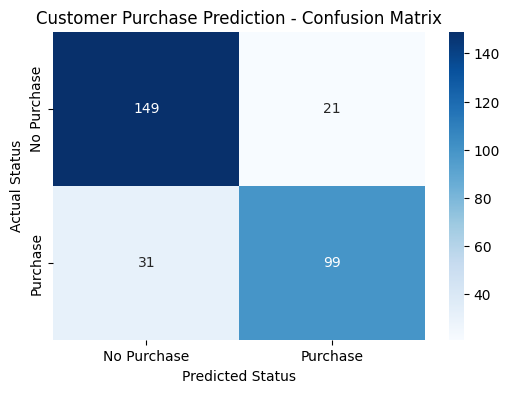

[[149  21]
 [ 31  99]]


In [ ]:
# Import evaluation and visualization libraries
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Plot the matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

# Add the title and axis labels
plt.title("Customer Purchase Prediction - Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")

# Display the graph
plt.show()

# Print the matrix values
print(cm)

12.Classification report

In [ ]:
# Import the classification report function
from sklearn.metrics import classification_report

# Display precision, recall, F1-score and support
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

              precision    recall  f1-score   support

 No Purchase       0.83      0.88      0.85       170
    Purchase       0.82      0.76      0.79       130

    accuracy                           0.83       300
   macro avg       0.83      0.82      0.82       300
weighted avg       0.83      0.83      0.83       300



13. Visualize purchase distribution

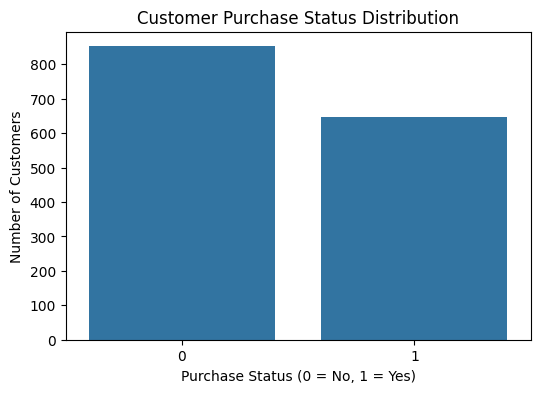

In [ ]:
# Count customers in each purchase category
purchase_counts = df["PurchaseStatus"].value_counts().sort_index()

# Create a bar chart
plt.figure(figsize=(6, 4))
sns.barplot(
    x=purchase_counts.index,
    y=purchase_counts.values
)

# Add chart title and labels
plt.title("Customer Purchase Status Distribution")
plt.xlabel("Purchase Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

# Display the graph
plt.show()

14. Saving the Trained Model

In [ ]:
# Import joblib to save machine learning objects
import joblib

# Save the trained model
joblib.dump(model, "customer_purchase_model.pkl")

# Save the fitted scaler
joblib.dump(scaler, "customer_purchase_scaler.pkl")

# Display confirmation
print("Model and scaler saved successfully!")

Model and scaler saved successfully!
